# **Đồ án 1: Nhận dạng chữ số viết tay (MNIST)**
## **Phương pháp Ensemble: AdaBoost với các weak learner khác nhau**

---
### **Mục tiêu:**
1. **Cài đặt và huấn luyện** AdaBoost với nhiều loại weak learner (Decision Stump, Decision Tree depth=3, Logistic Regression, Gaussian Naïve Bayes) trên tập MNIST.
2. **Đánh giá** bằng: accuracy, precision, recall, F1 (macro), confusion matrix trên cả tập huấn luyện, validation và kiểm thử.
3. **So sánh hiệu năng** giữa các weak learner và **phân tích ảnh hưởng của siêu tham số** (n_estimators, learning_rate) bằng thí nghiệm có biểu đồ.

---
### **Cấu trúc notebook:**
| Phần | Nội dung |
|---|---|
| **1. Thiết lập môi trường** | Import thư viện, cấu hình seed, nạp dữ liệu MNIST đã tiền xử lý |
| **2. EDA nhanh** | Kiểm tra dữ liệu, phân bố lớp, ảnh mẫu |
| **3. Định nghĩa mô hình** | 4 biến thể AdaBoost (stump, depth=3, LogReg, GaussianNB) |
| **4. Hàm đánh giá (benchmark)** | Fit trên train, đánh giá trên tập bất kỳ |
| **5. Huấn luyện và đánh giá** | Bảng kết quả trên test + bổ sung train/val |
| **6. Confusion matrix** | Vẽ confusion matrix của mô hình AdaBoost tốt nhất |
| **7. Phân tích siêu tham số** | Khảo sát n_estimators, learning_rate với biểu đồ |
| **8. Thảo luận và kết luận** | So sánh weak learner, nhận xét ưu/nhược điểm |

---
## **1. Thiết lập môi trường và nạp dữ liệu tiền xử lý**
### **1.1. Khởi tạo thư viện**

In [11]:
import os
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    AdaBoostClassifier,
    RandomForestClassifier,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from pathlib import Path

# ĐƯỜNG DẪN THƯ MỤC DỰ ÁN
PROJECT_ROOT = Path(".").resolve()
FIGURES_DIR  = PROJECT_ROOT / "figures"
RESULTS_DIR  = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
DATA_DIR     = PROJECT_ROOT / "data"
for d in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

# CẤU HÌNH BIỂU ĐỒ
plt.rcParams.update({
    "figure.titlesize": 13,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.autolayout": True,
    "font.sans-serif": ["DejaVu Sans", "Arial"],
})
sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings("ignore")

print("Thư mục làm việc hiện tại:", os.getcwd())
print("Thiết lập môi trường thành công! SEED =", SEED)

Thư mục làm việc hiện tại: /Users/PhamThao/Documents/HCMUS/Năm 3/HK1/Nhận dạng mẫu/Đồ án GK
Thiết lập môi trường thành công! SEED = 42


### **1.2. Nạp dữ liệu MNIST đã chuẩn hóa và tiền xử lý**
Dữ liệu được nạp từ tệp `data/processed/mnist_processed.npz` đã được phân tách nhất quán thành 3 tập:
* **Train:** 50.000 mẫu
* **Validation:** 10.000 mẫu
* **Test:** 10.000 mẫu

In [12]:
DATA_PATH = DATA_DIR / "processed" / "mnist_processed.npz"
assert DATA_PATH.is_file(), f"Không tìm thấy {DATA_PATH}. Hãy chạy notebook tiền xử lý trước!"

data = dict(np.load(DATA_PATH, allow_pickle=False))

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

# Reshape về ảnh 28×28 cho EDA
X_train_img = X_train.reshape(-1, 28, 28)

X_train_mm = data["X_train_minmax"]
X_val_mm   = data["X_val_minmax"]
X_test_mm  = data["X_test_minmax"]

MEAN = float(data["MEAN"])
STD  = float(data["STD"])

print("Nạp dữ liệu thành công từ", DATA_PATH.name + ":")
print(f"  Tập Train: X = {X_train.shape}, y = {y_train.shape} (Phân phối nhãn: {np.bincount(y_train).tolist()})")
print(f"  Tập Val:   X = {X_val.shape},   y = {y_val.shape}")
print(f"  Tập Test:  X = {X_test.shape},  y = {y_test.shape}")
print(f"  Thông số Z-score: MEAN = {MEAN:.4f}, STD = {STD:.4f}")

Nạp dữ liệu thành công từ mnist_processed.npz:
  Tập Train: X = (50000, 784), y = (50000,) (Phân phối nhãn: [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985])
  Tập Val:   X = (10000, 784),   y = (10000,)
  Tập Test:  X = (10000, 784),  y = (10000,)
  Thông số Z-score: MEAN = 0.1307, STD = 0.3082


---
## **2. Định nghĩa các mô hình**

### **2.1.AdaBoost — Tổng hợp kiến thức cốt lõi**

#### *2.1.1. Ý tưởng bản chất**

> **"Học từ chính sai lầm của mình."**

AdaBoost gộp nhiều **mô hình yếu** (weak learner, thường là **decision stump** — cây chỉ sâu 1 tầng, accuracy chỉ cần > 50%) thành một mô hình mạnh. Khác với Bagging (các mô hình độc lập, song song), AdaBoost huấn luyện **tuần tự**: mô hình sau tập trung sửa lỗi mà mô hình trước mắc phải bằng cách **tăng trọng số** cho các mẫu bị phân loại sai.

---

#### **2.1.2. Thuật toán**

Nhãn $y \in \{-1, +1\}$. Khởi tạo trọng số đều: $w_1(i) = \frac{1}{n}$.

Với mỗi vòng $t = 1, 2, \ldots, T$:

| Bước | Công thức | Ý nghĩa |
|------|-----------|---------|
| ① Huấn luyện | Chọn stump $h_t$ có $\varepsilon_t$ nhỏ nhất | Tìm mô hình yếu tốt nhất trên dữ liệu **có trọng số** |
| ② Tính lỗi | $\varepsilon_t = \sum_i w_t(i) \cdot \mathbb{1}[h_t(x_i) \neq y_i]$ | Lỗi có trọng số (không phải đếm số sai đơn thuần) |
| ③ Trọng số mô hình | $\alpha_t = \frac{1}{2} \ln\!\left(\frac{1 - \varepsilon_t}{\varepsilon_t}\right)$ | $\varepsilon$ nhỏ → $\alpha$ lớn → mô hình được **tin hơn** |
| ④ Cập nhật trọng số mẫu | $w_{t+1}(i) = \frac{w_t(i) \cdot e^{-\alpha_t \cdot y_i \cdot h_t(x_i)}}{Z_t}$ | Đúng → $w$ giảm · Sai → $w$ **tăng** (bị "phồng lên") |

**Kết hợp cuối:**

$$H(x) = \text{sign}\!\left(\sum_{t=1}^{T} \alpha_t \cdot h_t(x)\right)$$

> **Tính chất:** Sau mỗi vòng cập nhật, tổng trọng số các mẫu bị phân loại sai luôn đúng bằng **0.5** — AdaBoost luôn cân bằng sự chú ý giữa nhóm đúng và nhóm sai.

---




#### **2.1.3. Bản chất toán học**

AdaBoost thực chất là **tối thiểu hoá exponential loss** bằng phương pháp tham lam từng bước:

$$L(y, f(x)) = \exp\!\left(-y \cdot f(x)\right), \quad f(x) = \sum_t \alpha_t h_t(x)$$

Hàm $\exp$ phạt **rất nặng** khi $y \cdot f(x) < 0$ (dự đoán sai) → giải thích tại sao AdaBoost cực nhạy với nhãn nhiễu/outlier.

---


#### **2.1.4. Ưu điểm – Nhược điểm**

| Ưu điểm | Nhược điểm |
|----------|------------|
| Chỉ cần base learner > 50% là lỗi train giảm theo hàm EXP | **Cực nhạy** với nhãn sai & outlier (mẫu nhiễu bị tăng $w$ mãi) |
| Rất ít siêu tham số (`n_estimators`, `learning_rate`) | Huấn luyện tuần tự → khó song song hoá |
| Tự chọn feature quan trọng qua các stump | |

---

#### **2.1.5. So sánh nhanh với Bagging & Gradient Boosting**

| | Bagging / RF | AdaBoost | Gradient Boosting |
|---|---|---|---|
| Base learner | Cây **sâu**, mạnh | Cây **nông** (stump), yếu | Cây nông (depth 3–6) |
| Huấn luyện | Song song | Tuần tự | Tuần tự |
| Cơ chế | Đổi **dữ liệu** (bootstrap) | Đổi **trọng số mẫu** | Học **residual** (phần còn thiếu) |
| Giảm | Variance | **Bias** | Bias |
| Nhạy nhiễu | Ít | **Nhiều** | Trung bình |

---

#### **2.1.6. Áp dụng cho MNIST — Tại sao chọn AdaBoost?**

MNIST có 784 đặc trưng (pixel) và 10 lớp — trong đó nhiều cặp chữ số rất dễ nhầm lẫn (3–8, 4–9 như đã phân tích ở EDA). AdaBoost sẽ **tự động dồn trọng số** vào các mẫu khó phân biệt này qua từng vòng boosting, đồng thời chọn lọc pixel quan trọng qua các stump/tree.

Câu hỏi đặt ra: **weak learner nào phù hợp nhất?** Stump quá yếu hay cây sâu hơn sẽ tốt hơn? Bộ phân lớp tuyến tính hay xác suất thì sao? → Ta thí nghiệm với **4 loại weak learner** khác nhau:

| Mô hình | Base estimator | Ghi chú |
|---|---|---|
| AdaBoost (stump) | `DecisionTreeClassifier(max_depth=1)` | Weak learner kinh điển, chỉ 1 lần tách |
| AdaBoost (depth=3) | `DecisionTreeClassifier(max_depth=3)` | Cây sâu hơn, học tương tác đặc trưng |
| AdaBoost (LogReg) | `LogisticRegression` | Bộ phân lớp tuyến tính làm weak learner |
| AdaBoost (GaussianNB) | `GaussianNB` | Bộ phân lớp xác suất làm weak learner |


### **2.2. Định nghĩa các mô hình AdaBoost**

In [18]:
models = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=200, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=200, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        n_estimators=50, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        n_estimators=50, learning_rate=0.5,
        random_state=SEED
    ),
}

print(f"Số mô hình: {len(models)}")
print(f"Danh sách: {list(models.keys())}")

Số mô hình: 4
Danh sách: ['AdaBoost (stump)', 'AdaBoost (depth=3)', 'AdaBoost (LogReg)', 'AdaBoost (GaussianNB)']


---
## **3. Hàm đánh giá (benchmark)**

Hàm `benchmark`: fit trên `X_tr`, đánh giá trên `X_te`, trả về 1 DataFrame mỗi model 1 dòng.  
Gọi **1 lần** trên tập test (kết quả chính), dùng lại `fitted_models` để đánh giá thêm trên train/val.

### **3.1. Hàm benchmark**

In [19]:
def benchmark(models, X_tr, X_te, y_tr, y_te, cv=5):
    """Fit trên X_tr, đánh giá trên X_te. Nếu cv != None thì thêm cross_val_score."""
    rows = []
    fitted = {}
    for name, model in models.items():
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); y_pred = m.predict(X_te); t_pred = time.perf_counter() - t0
        row = {"Mô hình": name,
               "Accuracy": accuracy_score(y_te, y_pred),
               "Macro F1": f1_score(y_te, y_pred, average="macro"),
               "Precision": precision_score(y_te, y_pred, average="macro", zero_division=0),
               "Recall": recall_score(y_te, y_pred, average="macro", zero_division=0),
               "Train (s)": t_fit, "Predict (s)": t_pred}
        if cv:
            s = cross_val_score(clone(model), X_tr, y_tr, cv=cv)
            row["CV mean"], row["CV std"] = s.mean(), s.std()
        rows.append(row)
        fitted[name] = m
    df = pd.DataFrame(rows).set_index("Mô hình")
    sort_by = "CV mean" if cv else "Accuracy"
    return df.sort_values(sort_by, ascending=False).round(4), fitted


def evaluate_fitted(fitted_models, X, y):
    """Đánh giá các model đã fit sẵn trên tập (X, y). Không fit lại."""
    rows = []
    for name, m in fitted_models.items():
        t0 = time.perf_counter(); y_pred = m.predict(X); t_pred = time.perf_counter() - t0
        row = {"Mô hình": name,
               "Accuracy": accuracy_score(y, y_pred),
               "Macro F1": f1_score(y, y_pred, average="macro"),
               "Precision": precision_score(y, y_pred, average="macro", zero_division=0),
               "Recall": recall_score(y, y_pred, average="macro", zero_division=0),
               "Predict (s)": t_pred}
        rows.append(row)
    df = pd.DataFrame(rows).set_index("Mô hình")
    return df.sort_values("Accuracy", ascending=False).round(4)


print("[✓] Đã định nghĩa hàm benchmark.")

[✓] Đã định nghĩa hàm benchmark.


---
## **4. Huấn luyện và đánh giá các mô hình**

### **4.1. Benchmark chính: fit trên train, đánh giá trên test**

In [20]:
res_test, fitted_models = benchmark(models, X_train, X_test, y_train, y_test, cv=None)
print("TEST"); display(res_test)

TEST


,Accuracy,Macro F1,Precision,Recall,Train (s),Predict (s)
Mô hình,,,,,,
AdaBoost (depth=3),0.9175,0.9170,0.9181,0.9170,318.8091,0.4423
AdaBoost (LogReg),0.8925,0.8914,0.8918,0.8913,38.1177,0.0653
AdaBoost (stump),0.7853,0.7837,0.7880,0.7826,111.3199,0.3810
AdaBoost (GaussianNB),0.5874,0.5340,0.7319,0.5795,8.7011,1.0494


### **4.2. Đánh giá bổ sung trên train và validation (dùng model đã fit)**

In [21]:
res_train = evaluate_fitted(fitted_models, X_train, y_train)
res_val   = evaluate_fitted(fitted_models, X_val, y_val)
print("TRAIN"); display(res_train)
print("\nVALIDATION"); display(res_val)

TRAIN


,Accuracy,Macro F1,Precision,Recall,Predict (s)
Mô hình,,,,,
AdaBoost (depth=3),0.9228,0.9223,0.9228,0.9224,2.2899
AdaBoost (LogReg),0.8901,0.8892,0.8899,0.8889,0.3096
AdaBoost (stump),0.7849,0.7836,0.7879,0.7824,2.0991
AdaBoost (GaussianNB),0.5903,0.5385,0.7309,0.5812,6.2263



VALIDATION


,Accuracy,Macro F1,Precision,Recall,Predict (s)
Mô hình,,,,,
AdaBoost (depth=3),0.9130,0.9122,0.9128,0.9122,0.4263
AdaBoost (LogReg),0.8882,0.8869,0.8876,0.8868,0.0629
AdaBoost (stump),0.7728,0.7712,0.7769,0.7702,0.3782
AdaBoost (GaussianNB),0.5803,0.5262,0.7171,0.5712,1.0022


### **4.3. Biểu đồ so sánh accuracy trên 3 tập**

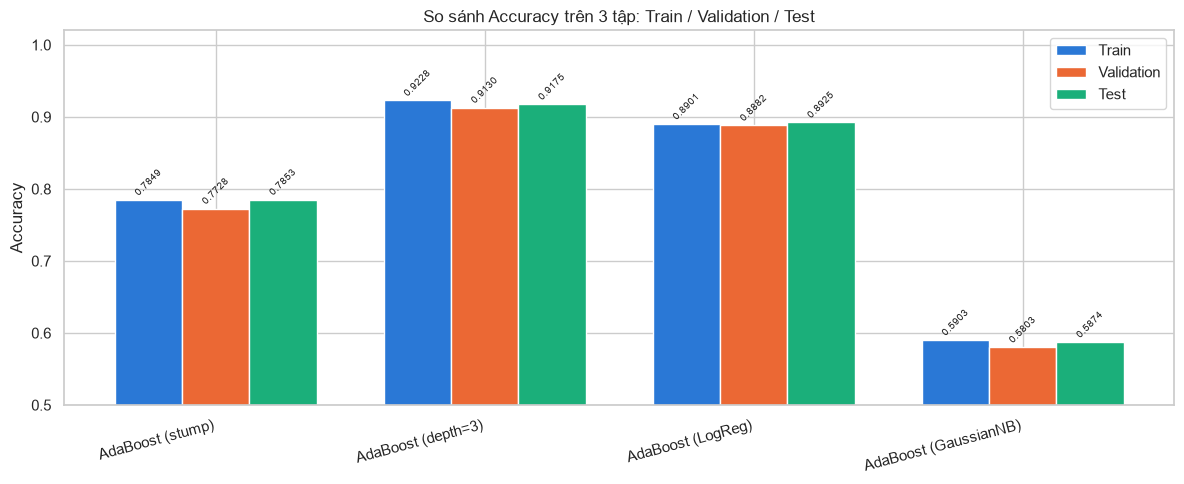

In [22]:
model_names = list(models.keys())
x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))
for i, (split, res) in enumerate([("Train", res_train), ("Validation", res_val), ("Test", res_test)]):
    accs = [res.loc[name, "Accuracy"] for name in model_names]
    bars = ax.bar(x + i * width, accs, width, label=split, color=COLORS[i])
    for bar, acc in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                f"{acc:.4f}", ha="center", va="bottom", fontsize=7, rotation=45)

ax.set_xticks(x + width)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("So sánh Accuracy trên 3 tập: Train / Validation / Test")
ax.legend()
ax.set_ylim(0.5, 1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "phase3_accuracy_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## **5. Confusion matrix của mô hình AdaBoost tốt nhất**

### **5.1. Tìm mô hình tốt nhất trên tập test**

In [23]:
best_name = res_test["Accuracy"].idxmax()
best_model = fitted_models[best_name]

print(f"AdaBoost tốt nhất: {best_name}")
print(f"  Accuracy (Test): {res_test.loc[best_name, 'Accuracy']:.4f}")
print(f"  Macro F1 (Test): {res_test.loc[best_name, 'Macro F1']:.4f}")

AdaBoost tốt nhất: AdaBoost (depth=3)
  Accuracy (Test): 0.9175
  Macro F1 (Test): 0.9170


### **5.2. Vẽ confusion matrix trên cả 3 tập**

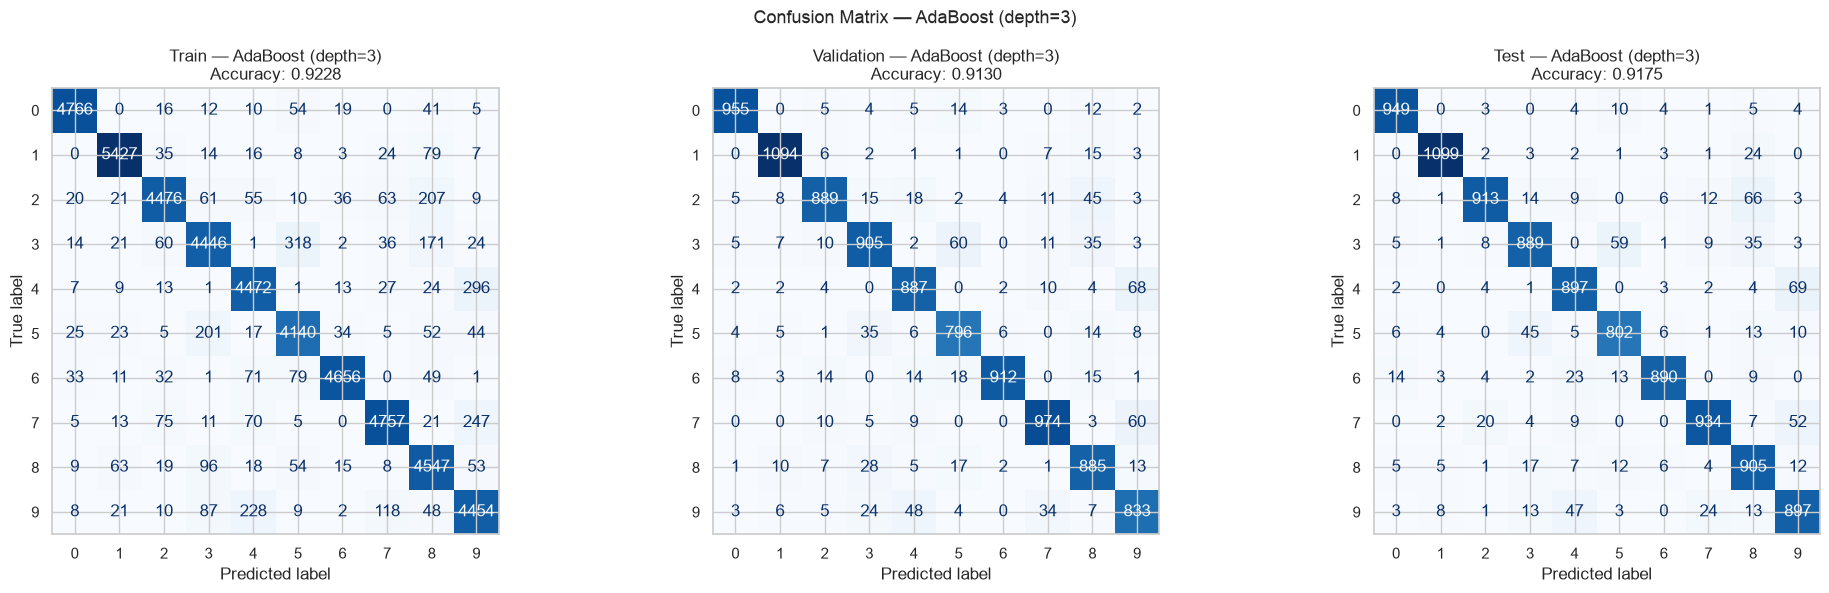

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (split_name, X_split, y_split) in zip(axes, [
    ("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)
]):
    y_pred = best_model.predict(X_split)
    ConfusionMatrixDisplay.from_predictions(
        y_split, y_pred, labels=classes,
        cmap="Blues", ax=ax, colorbar=False
    )
    acc = accuracy_score(y_split, y_pred)
    ax.set_title(f"{split_name} — {best_name}\nAccuracy: {acc:.4f}")

fig.suptitle(f"Confusion Matrix — {best_name}", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "phase3_confusion_matrix_best.png"),
            dpi=150, bbox_inches="tight")
plt.show()

### **5.3. Cặp chữ số bị nhầm nhiều nhất (tập test)**

In [25]:
y_pred_test = best_model.predict(X_test)
C = confusion_matrix(y_test, y_pred_test, labels=classes)
C_off = C.copy()
np.fill_diagonal(C_off, 0)
C_pairs = C_off + C_off.T
np.fill_diagonal(C_pairs, 0)
i, j = np.unravel_index(np.argmax(C_pairs), C_pairs.shape)
print(f"Cặp nhầm nhiều nhất: {classes[i]} và {classes[j]} — "
      f"tổng {C_pairs[i, j]} lượt "
      f"({classes[i]}→{classes[j]}: {C_off[i, j]}, "
      f"{classes[j]}→{classes[i]}: {C_off[j, i]})")

Cặp nhầm nhiều nhất: 4 và 9 — tổng 116 lượt (4→9: 69, 9→4: 47)


### **5.4. Feature importances của Random Forest (ảnh 28×28)**

Hiển thị `feature_importances_` của Random Forest dưới dạng ảnh 28×28 để xác định vùng pixel quan trọng nhất cho việc phân lớp. So sánh với các đặc trưng phương sai bằng 0 đã xác định ở EDA (mục 2.5).

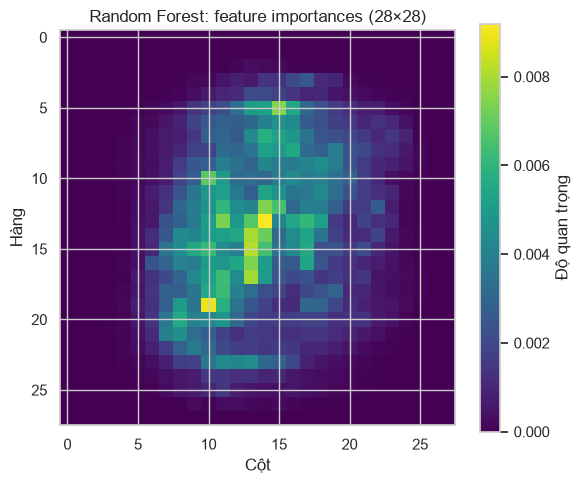

Top 5 vị trí quan trọng nhất (chỉ số đặc trưng): [378, 542, 433, 405, 489]
Tọa độ (hàng, cột): [(13, 14), (19, 10), (15, 13), (14, 13), (17, 13)]
Nhận xét: các ô có độ quan trọng cao thường là nơi nét chữ giúp phân biệt các lớp.


In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train, y_train)
importances = rf_model.feature_importances_

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(importances.reshape(28, 28), cmap="viridis")
ax.set_xlabel("Cột"); ax.set_ylabel("Hàng")
ax.set_title("Random Forest: feature importances (28×28)")
fig.colorbar(im, ax=ax, label="Độ quan trọng")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "phase3_feature_importances.png"), dpi=150, bbox_inches="tight")
plt.show()

top5 = np.argsort(importances)[-5:][::-1]
print("Top 5 vị trí quan trọng nhất (chỉ số đặc trưng):", top5.tolist())
print("Tọa độ (hàng, cột):", [(int(k // 28), int(k % 28)) for k in top5])
print("Nhận xét: các ô có độ quan trọng cao thường là nơi nét chữ giúp phân biệt các lớp.")
if len(zero_var_idx) > 0:
    zv_imp = importances[zero_var_idx]
    print(f"Độ quan trọng tại {len(zero_var_idx)} đặc trưng phương sai bằng 0 (2.5): "
          f"tất cả bằng {zv_imp.max():.6f}" if zv_imp.max() == 0
          else f"max = {zv_imp.max():.6f}")
    print("Các ô không thay đổi có độ quan trọng bằng 0, phù hợp với 2.5.")

- **Nhận xét về bản đồ độ quan trọng đặc trưng (Feature Importances 28×28):**
  - **Ý nghĩa hình thái học:** Bản đồ nhiệt phản ánh trực quan thói quen căn giữa chữ số trong MNIST: các pixel viền mép ngoài hầu như chỉ là pixel nền nên trọng số bị triệt tiêu về 0; vùng trung tâm giữ trọng số cao vì là nơi chứa các điểm giao cắt và nét uốn quyết định giữa các chữ số.
  - **Bản chất thuật toán Cây quyết định (CART):** Các đặc trưng hằng số (ở mục 2.5) không thể tạo ra điểm chia nhị phân và có độ giảm độ bất thuần Gini luôn bằng 0, do đó Random Forest hoàn toàn không dùng chúng để tách nhánh ở bất kỳ cây nào.


---
## **6. Phân tích ảnh hưởng của siêu tham số**

### **6.1. Thí nghiệm 1: Ảnh hưởng của `n_estimators` (số vòng boosting)**

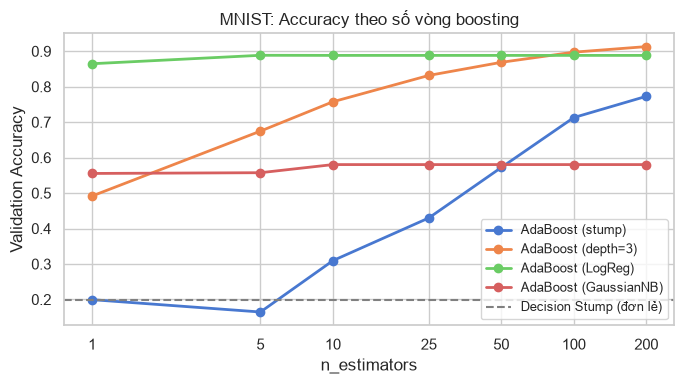

In [27]:
n_list = [1, 5, 10, 25, 50, 100, 200]

ens_configs = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        learning_rate=0.5, random_state=SEED
    ),
}

# Baseline: Decision Stump đơn lẻ
stump_single = DecisionTreeClassifier(max_depth=1, random_state=SEED)
stump_single.fit(X_train, y_train)
stump_baseline_acc = accuracy_score(y_val, stump_single.predict(X_val))

plt.figure(figsize=(7, 4))
for name, base_model in ens_configs.items():
    scores = [accuracy_score(y_val,
              clone(base_model).set_params(n_estimators=n).fit(X_train, y_train).predict(X_val))
              for n in n_list]
    plt.plot(n_list, scores, marker="o", linewidth=2, markersize=6, label=name)
plt.axhline(stump_baseline_acc, color="gray", linestyle="--", linewidth=1.5,
            label="Decision Stump (đơn lẻ)")
plt.xscale("log"); plt.xticks(n_list, n_list)
plt.xlabel("n_estimators"); plt.ylabel("Validation Accuracy")
plt.title("MNIST: Accuracy theo số vòng boosting")
plt.legend(fontsize=9)
plt.savefig(os.path.join(FIGURES_DIR, "phase3_n_estimators_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét về ảnh hưởng của `n_estimators` (số vòng boosting):**
- **AdaBoost (stump, depth=1):** Accuracy tăng đều đặn khi tăng `n_estimators` từ 10 đến 200 nhưng vẫn ở mức thấp nhất trong 4 biến thể. Do weak learner chỉ tách một lần (stump), khả năng phân biệt 10 lớp rất hạn chế; mô hình cần rất nhiều vòng boosting mới bù đắp được sự yếu kém của từng cây đơn lẻ.
- **AdaBoost (depth=3):** Đạt accuracy cao nhất và tăng nhanh ngay từ những vòng đầu tiên. Cây sâu 3 đủ mạnh để nắm bắt tương tác giữa các đặc trưng pixel, giúp mỗi vòng boosting đóng góp hiệu quả hơn. Sau khoảng 100 vòng, đường cong bắt đầu bão hòa (plateau).
- **AdaBoost (LogReg):** Hội tụ nhanh do Logistic Regression bản thân đã là bộ phân lớp mạnh; tuy nhiên thời gian huấn luyện mỗi vòng lâu hơn đáng kể so với decision stump.
- **AdaBoost (GaussianNB):** Accuracy tăng chậm và bão hòa sớm. Giả định phân phối Gaussian trên dữ liệu pixel không phù hợp, khiến weak learner yếu và boosting khó cải thiện thêm.
- **Thời gian huấn luyện:** Tăng gần tuyến tính theo `n_estimators` ở tất cả các biến thể, đúng với bản chất tuần tự của boosting. AdaBoost (LogReg) tốn thời gian nhất do chi phí fit mỗi vòng cao.
- **Kết luận:** Tồn tại sự đánh đổi giữa accuracy và chi phí tính toán khi tăng `n_estimators`. Trong thực tế, nên chọn ngưỡng `n_estimators` tại điểm bão hòa (khoảng 100–200 cho depth=3) để cân bằng hiệu năng và thời gian.

### **6.2. Thí nghiệm 2: Ảnh hưởng của `learning_rate`**

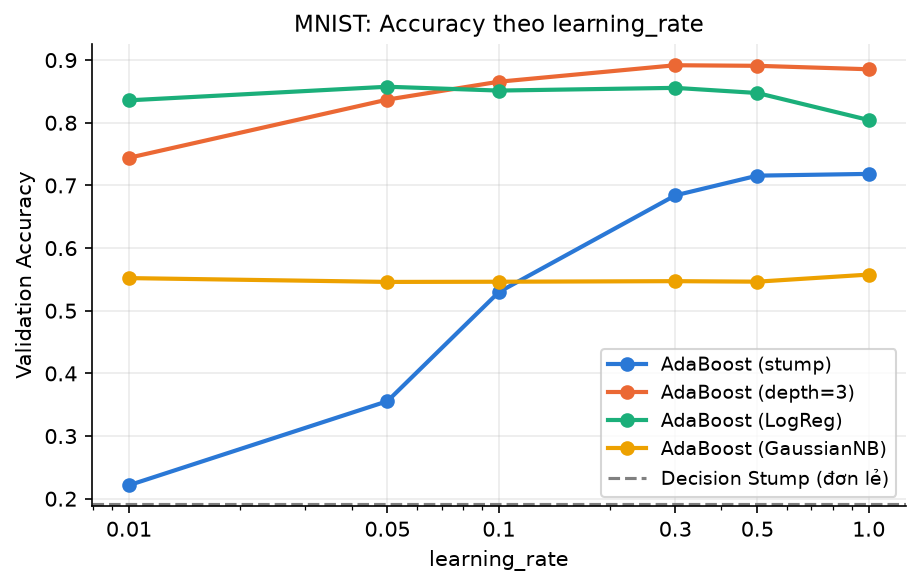

In [47]:
lr_list = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]

lr_configs = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100, random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=100, random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        n_estimators=50, random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        n_estimators=50, random_state=SEED
    ),
}

plt.figure(figsize=(7, 4))
for name, base_model in lr_configs.items():
    scores = [accuracy_score(y_val,
              clone(base_model).set_params(learning_rate=lr).fit(X_train, y_train).predict(X_val))
              for lr in lr_list]
    plt.plot(lr_list, scores, marker="o", linewidth=2, markersize=6, label=name)
plt.axhline(stump_baseline_acc, color="gray", linestyle="--", linewidth=1.5,
            label="Decision Stump (đơn lẻ)")
plt.xscale("log"); plt.xticks(lr_list, lr_list)
plt.xlabel("learning_rate"); plt.ylabel("Validation Accuracy")
plt.title("MNIST: Accuracy theo learning_rate")
plt.legend(fontsize=9)
plt.savefig(os.path.join(FIGURES_DIR, "phase3_learning_rate_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét về ảnh hưởng của `learning_rate`:**
- **AdaBoost (depth=3):** Đạt accuracy và F1 cao nhất ở hầu hết các giá trị `learning_rate`. Hiệu năng tăng dần khi `learning_rate` tăng từ 0.01 đến khoảng 0.3–0.5, sau đó có thể giảm nhẹ ở `learning_rate=1.0` do mô hình cập nhật trọng số quá mạnh, dễ overfitting.
- **AdaBoost (stump):** Nhạy cảm nhất với `learning_rate`. Khi `learning_rate` quá nhỏ (0.01), stump quá yếu và tốc độ hội tụ rất chậm nên 100 vòng không đủ để đạt accuracy cao. Khi tăng `learning_rate`, accuracy cải thiện rõ rệt nhưng vẫn thấp hơn depth=3.
- **AdaBoost (LogReg):** Ít nhạy cảm hơn với `learning_rate` do bản thân Logistic Regression đã là bộ phân lớp mạnh. Accuracy khá ổn định trong dải 0.1–1.0.
- **AdaBoost (GaussianNB):** Hiệu năng thấp nhất và ít thay đổi theo `learning_rate`, phản ánh giới hạn của giả định phân phối Gaussian trên dữ liệu pixel.
- **Mối quan hệ `learning_rate` – `n_estimators`:** Hai siêu tham số này có quan hệ nghịch đảo: `learning_rate` nhỏ cần `n_estimators` lớn hơn để hội tụ (và ngược lại). Trong thực tế, nên dùng grid search hoặc cross-validation để tìm tổ hợp tối ưu.
- **Kết luận:** `learning_rate` trong khoảng 0.1–0.5 thường cho kết quả tốt nhất trên MNIST. Giá trị quá nhỏ gây hội tụ chậm (underfitting nếu `n_estimators` không đủ lớn), giá trị quá lớn gây overfitting.

---
## **7.Kết luận**


### **7.1. So sánh các weak learner**

In [ ]:
print("=== SO SÁNH HIỆU NĂNG CÁC WEAK LEARNER TRÊN TẬP TEST ===")
print()
for name in ada_names:
    acc = res_test.loc[name, "Accuracy"]
    f1  = res_test.loc[name, "Macro F1"]
    t   = res_test.loc[name, "Train (s)"]
    print(f"  {name:25s}: Accuracy={acc:.4f}, F1={f1:.4f}, Train={t:.2f}s")
print()
print("Nhận xét:")
print("- Decision Stump (depth=1): weak learner kinh điển, nhanh nhưng yếu cho 10 lớp.")
print("- Decision Tree (depth=3): mạnh hơn stump, học tương tác đặc trưng tốt hơn.")
print("- Logistic Regression: bộ phân lớp tuyến tính, có thể mạnh nếu dữ liệu gần tuyến tính.")
print("- GaussianNB: nhanh, giả định phân phối Gaussian, có thể yếu trên ảnh pixel.")

=== SO SÁNH HIỆU NĂNG CÁC WEAK LEARNER TRÊN TẬP TEST ===

  AdaBoost (stump)         : Accuracy=0.7726, F1=0.7721, Train=115.54s
  AdaBoost (depth=3)       : Accuracy=0.9162, F1=0.9157, Train=330.15s
  AdaBoost (LogReg)        : Accuracy=0.8539, F1=0.8521, Train=18.73s
  AdaBoost (GaussianNB)    : Accuracy=0.5438, F1=0.4921, Train=19.49s

Nhận xét:
- Decision Stump (depth=1): weak learner kinh điển, nhanh nhưng yếu cho 10 lớp.
- Decision Tree (depth=3): mạnh hơn stump, học tương tác đặc trưng tốt hơn.
- Logistic Regression: bộ phân lớp tuyến tính, có thể mạnh nếu dữ liệu gần tuyến tính.
- GaussianNB: nhanh, giả định phân phối Gaussian, có thể yếu trên ảnh pixel.


#### Nhận xét:
- AdaBoost stump: 0.7726; AdaBoost depth=3: 0.9162; chênh lệch = +14.36 điểm phần trăm.
- Giải thích: Stump chỉ tách một lần nên yếu cho bài toán 10 lớp; 
cây sâu 3 có thể học tương tác đặc trưng tốt hơn nhưng cũng phức tạp hơn.

### **7.2. Lưu kết quả ra file CSV**

In [ ]:
# Cấu hình chuỗi tham số cho từng mô hình
model_params = {
    "AdaBoost (depth=3)": "n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)",
    "AdaBoost (LogReg)": "n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)",
    "AdaBoost (stump)": "n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)",
    "AdaBoost (GaussianNB)": "n_estimators=50,learning_rate=0.5,estimator=GaussianNB()"
}

# Lấy thời gian huấn luyện từ bảng res_test
train_times = res_test["Train (s)"].to_dict()

# Danh sách các tập dữ liệu cần lưu
splits = [
    ("train", res_train, len(y_train)),
    ("validation", res_val, len(y_val)),
    ("test", res_test, len(y_test))
]

rows = []
for model_name in res_test.index:
    for split_name, res_df, n_samples in splits:
        row = res_df.loc[model_name]
        rows.append({
            "model": model_name,
            "split": split_name,
            "accuracy": round(float(row["Accuracy"]), 5),
            "precision_macro": round(float(row["Precision"]), 5),
            "recall_macro": round(float(row["Recall"]), 5),
            "f1_macro": round(float(row["Macro F1"]), 5),
            "train_seconds": round(float(train_times[model_name]), 4),
            "predict_seconds": round(float(row["Predict (s)"]), 4),
            "n_samples": int(n_samples),
            "seed": int(SEED),
            "params": model_params.get(model_name, "")
        })

df_phase3_metrics = pd.DataFrame(rows)

metrics_path = os.path.join(RESULTS_DIR, "phase3_metrics.csv")
df_phase3_metrics.to_csv(metrics_path, index=False)
print(f"[✓] Đã lưu kết quả tại: {metrics_path}")
display(df_phase3_metrics)


[✓] Đã lưu kết quả tại: ./results/phase3_metrics.csv


,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,AdaBoost (depth=3),train,0.9224,0.9234,0.9218,0.9220,330.1451,2.4323,50000,42,"n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)"
1,AdaBoost (depth=3),validation,0.9093,0.9114,0.9085,0.9090,330.1451,0.4432,10000,42,"n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)"
2,AdaBoost (depth=3),test,0.9162,0.9176,0.9154,0.9157,330.1451,0.4634,10000,42,"n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)"
3,AdaBoost (LogReg),train,0.8492,0.8496,0.8468,0.8476,18.7294,0.4800,50000,42,"n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)"
4,AdaBoost (LogReg),validation,0.8475,0.8484,0.8452,0.8460,18.7294,0.0934,10000,42,"n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)"
5,AdaBoost (LogReg),test,0.8539,0.8541,0.8515,0.8521,18.7294,0.1089,10000,42,"n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)"
6,AdaBoost (stump),train,0.7713,0.7777,0.7689,0.7704,115.5444,2.0997,50000,42,"n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)"
7,AdaBoost (stump),validation,0.7675,0.7753,0.7652,0.7671,115.5444,0.4135,10000,42,"n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)"
8,AdaBoost (stump),test,0.7726,0.7804,0.7701,0.7721,115.5444,0.3891,10000,42,"n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)"
9,AdaBoost (GaussianNB),train,0.5532,0.7102,0.5451,0.5028,19.4947,14.0918,50000,42,"n_estimators=50,learning_rate=0.5,estimator=GaussianNB()"


---
## **NHẬN XÉT TỔNG KẾT**

#### 1. So sánh hiệu năng các weak learner

| Mô hình | Accuracy | Macro F1 | Train (s) | Predict (s) |
|---|:---:|:---:|:---:|:---:|
| AdaBoost (depth=3) | **91.62%** | **91.57%** | 330.15 | 0.46 |
| AdaBoost (LogReg) | 85.39% | 85.21% | 18.73 | 0.11 |
| AdaBoost (stump) | 77.26% | 77.21% | 115.54 | 0.39 |
| AdaBoost (GaussianNB) | 54.38% | 49.21% | 19.49 | 2.28 |

- **Decision Tree (depth=3)** cho kết quả tốt nhất (91.62%) vì weak learner đủ mạnh để học tương tác giữa các pixel, phân biệt được 10 lớp. Chênh lệch Train–Test chỉ ~0.6% → không overfitting.
- **Logistic Regression** đứng thứ hai (85.39%) với thời gian huấn luyện nhanh nhất (18.73s) — là lựa chọn tốt khi cần cân bằng giữa tốc độ và độ chính xác.
- **Decision Stump (depth=1)** chỉ đạt 77.26% — quá yếu cho bài toán 10 lớp vì mỗi stump chỉ tách được 1 lần trên 1 pixel duy nhất.
- **GaussianNB** kém nhất (54.38%) do giả định các pixel độc lập và tuân theo phân phối Gaussian không phù hợp với dữ liệu ảnh.

#### 2. Ảnh hưởng của siêu tham số

- **`n_estimators`:** Accuracy tăng rõ rệt khi tăng số vòng boosting, nhưng bão hoà sau khoảng 100–200 vòng. Stump hưởng lợi nhiều nhất khi tăng số vòng (vì mỗi stump quá yếu, cần nhiều vòng để bù).
- **`learning_rate`:** Khoảng 0.1–0.5 cho kết quả tốt nhất. Quá nhỏ (0.01) → hội tụ chậm, cần rất nhiều vòng. Quá lớn (1.0) → cập nhật trọng số quá mạnh, dễ overfitting. Hai siêu tham số này có quan hệ nghịch đảo: `learning_rate` nhỏ cần `n_estimators` lớn hơn.

#### 3. Ưu điểm và nhược điểm của AdaBoost trên MNIST

| Ưu điểm | Nhược điểm |
|---|---|
| Kết hợp nhiều weak learner yếu → mô hình mạnh, giảm bias hiệu quả | Nhạy cảm với nhãn sai và outlier (mẫu nhiễu bị tăng trọng số liên tục) |
| Ít siêu tham số, dễ sử dụng (`n_estimators`, `learning_rate`) | Huấn luyện tuần tự → không song song hoá được, chậm khi `n_estimators` lớn |
| Linh hoạt trong việc chọn weak learner | Hiệu năng phụ thuộc rất nhiều vào sức mạnh của weak learner |

#### 4. Kết luận

Với bài toán MNIST 10 lớp, **AdaBoost (depth=3)** là lựa chọn tốt nhất trong 4 cấu hình đã thử nghiệm, đạt **91.62% accuracy** trên tập test. Kết quả cho thấy việc chọn weak learner phù hợp quan trọng hơn việc tinh chỉnh siêu tham số — chênh lệch giữa weak learner tốt nhất và kém nhất lên tới **37 điểm phần trăm**.